In [1]:
# Install library Sastrawi untuk NLP Bahasa Indonesia
!pip install Sastrawi nltk pandas openpyxl

import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Download stopwords NLTK
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
# Jika mengunggah langsung ke Colab:
from google.colab import files
uploaded = files.upload()

# Mendapatkan nama file yang baru saja diunggah secara otomatis
file_name = list(uploaded.keys())[0]
print(f"Membaca file: {file_name}")

# Membaca data sesuai dengan ekstensi file yang diunggah
if file_name.endswith('.csv'):
    df = pd.read_csv(file_name)
else:
    df = pd.read_excel(file_name, sheet_name=0) # atau tentukan sheet_name jika excel

print(f"Ukuran data awal: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head(3)

In [ ]:
# 1. Memperbaiki pergeseran kolom (hanya jika kolom Unnamed: 20 dan Unnamed: 21 tersedia)
if 'Unnamed: 20' in df.columns:
    df['Keyword'] = df['Keyword'].fillna(df['Unnamed: 20'])
if 'Unnamed: 21' in df.columns:
    df['Waktu Scrape'] = df['Waktu Scrape'].fillna(df['Unnamed: 21'])

# 2. Menghapus kolom yang tidak relevan / bernilai dominan kosong
kolom_dihapus = ['Unnamed: 20', 'Unnamed: 21', 'URL', 'Jenis Media']
df = df.drop(columns=[col for col in kolom_dihapus if col in df.columns])

# 3. Menghapus data duplikat berdasarkan 'ID Tweet'
if 'ID Tweet' in df.columns:
    df = df.drop_duplicates(subset=['ID Tweet']).reset_index(drop=True)

# 4. Penanganan Missing Values (Nilai Hilang)
for col in ['Views', 'Hashtag', 'Mention', 'Bahasa', 'Lokasi']:
    if col in df.columns:
        if col == 'Views':
            df[col] = df[col].fillna(0)
        elif col in ['Hashtag', 'Mention']:
            df[col] = df[col].fillna('Tidak Ada')
        elif col == 'Bahasa':
            df[col] = df[col].fillna('Indonesia')
        elif col == 'Lokasi':
            df[col] = df[col].fillna('Tidak Diketahui')

# 5. Konversi Tipe Data jika kolom tersedia
if 'Waktu Posting' in df.columns:
    df['Waktu Posting'] = pd.to_datetime(df['Waktu Posting'], errors='coerce')
if 'Views' in df.columns:
    df['Views'] = pd.to_numeric(df['Views'], errors='coerce').fillna(0).astype(int)

print(f"Ukuran data setelah pembersihan awal: {df.shape[0]} baris, {df.shape[1]} kolom")

Ukuran data setelah pembersihan awal: 4100 baris, 19 kolom


In [ ]:
# Inisialisasi Stopwords & Stemmer Bahasa Indonesia
stop_words = set(stopwords.words('indonesian'))

# Tambahkan kata-kata stopword khusus media sosial jika diperlukan
stop_words.update(['yg', 'utk', 'dgn', 'amp', 'rt', 'jd', 'sy', 'kalo', 'gak', 'nga', 'ngga'])

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    # 1. Lowercase (Mengubah ke huruf kecil)
    text = text.lower()

    # 2. Menghapus URL/Link
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # 3. Menghapus Mention (@username) dan Hashtag (#tag)
    text = re.sub(r'[@#]\w+', '', text)

    # 4. Menghapus Karakter Khusus, Angka, dan Tanda Baca
    text = re.sub(r'[^a-z\s]', '', text)

    # 5. Tokenisasi & Penghapusan Stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words and len(word) > 2]

    # 6. Rejoin Text (Gabungkan kembali)
    text_clean = ' '.join(words)

    # 7. Stemming (Mengubah ke kata dasar - opsional, aktifkan jika dibutuhkan)
    # text_clean = stemmer.stem(text_clean)

    return text_clean

# Terapkan fungsi preprocessing ke kolom 'Isi Tweet'
df['Isi_Tweet_Clean'] = df['Isi Tweet'].apply(preprocess_text)

# Menampilkan hasil komparasi sebelum dan sesudah
df[['Isi Tweet', 'Isi_Tweet_Clean']].head()

,Isi Tweet,Isi_Tweet_Clean
0,@jujurgueakuin Kami mohon maaf atas ketidaknya...,mohon maaf ketidaknyamannya kak terkait keluha...
1,@erinisheree @erinisheree Semoga jaringannya l...,semoga jaringannya lancar kak erin terkait kel...
2,@zhcnhchenle @zhcnhchenle Maaf Kak. Terkait ke...,maaf kak terkait keluhan sms spam pinjaman onl...
3,@Cocohuzelnutt @Cocohuzelnutt Halo Sahabat @ch...,halo sahabat mohon maaf ketidaknyamanannya men...
4,"OJK Terima 15.278 Pengaduan, Paling Banyak Kel...",ojk terima pengaduan keluhan pinjaman online i...


In [ ]:
output_file = 'keluhan_pinjol_preprocessed.xlsx'

# Menyimpan ke Excel
df.to_excel(output_file, index=False, engine='openpyxl')

# Unduh otomatis hasil ke komputer lokal melalui Colab
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Download stopwords
nltk.download('stopwords')

# 1. Membaca Data Preprocessed
filepath = 'keluhan_pinjol_preprocessed.xlsx'
df = pd.read_excel(filepath)

print("Memulai pembenahan pergeseran kolom...")

# Buat dataframe baru untuk menampung hasil perapihan
df_fixed = pd.DataFrame()

# Tentukan baris mana yang tergeser (Waktu Posting bertipe 1970/epoch)
is_shifted = df['Waktu Posting'].astype(str).str.startswith('1970-01-01')

# --- A. UNTUK BARIS NORMAL (BARIS 0 - 37) ---
df_normal = df[~is_shifted].copy()

# --- B. UNTUK BARIS TERGESER (BARIS 38 DST) ---
df_shift = df[is_shifted].copy()

# Perbaikan pemetaan nilai untuk data yang tergeser:
df_shift_corrected = pd.DataFrame()
df_shift_corrected['ID Tweet'] = df_shift['ID Tweet']
df_shift_corrected['Username'] = df_shift['Username']
df_shift_corrected['Handle'] = df_shift['Handle']
df_shift_corrected['User ID'] = df_shift['User ID']
df_shift_corrected['Followers'] = df_shift['Followers']
df_shift_corrected['Waktu Posting'] = pd.to_datetime(df_shift['Isi Tweet'], errors='coerce')
df_shift_corrected['Isi Tweet'] = df_shift['Likes']
df_shift_corrected['Likes'] = pd.to_numeric(df_shift['Reposts'], errors='coerce').fillna(0).astype(int)
df_shift_corrected['Reposts'] = pd.to_numeric(df_shift['Balasan'], errors='coerce').fillna(0).astype(int)
df_shift_corrected['Balasan'] = pd.to_numeric(df_shift['Views'], errors='coerce').fillna(0).astype(int)
df_shift_corrected['Views'] = pd.to_numeric(df_shift['Hashtag'], errors='coerce').fillna(0).astype(int)
df_shift_corrected['Hashtag'] = 'Tidak Ada'
df_shift_corrected['Mention'] = df_shift['Mention']
df_shift_corrected['Bahasa'] = df_shift['Lokasi']          # 'in' -> Bahasa Indonesia
df_shift_corrected['Lokasi'] = df_shift['ID Percakapan']    # Nama kota / lokasi
df_shift_corrected['ID Percakapan'] = np.nan
df_shift_corrected['Keyword'] = df_shift['Keyword']
df_shift_corrected['Waktu Scrape'] = df_shift['Waktu Scrape']

# Gabungkan kembali baris normal dan baris yang sudah diperbaiki
df_fixed = pd.concat([df_normal.drop(columns=['Isi_Tweet_Clean'], errors='ignore'), df_shift_corrected], ignore_index=True)

# Format ulang tipe data Waktu Posting
df_fixed['Waktu Posting'] = pd.to_datetime(df_fixed['Waktu Posting'], errors='coerce')

# Normalize nilai Bahasa
df_fixed['Bahasa'] = df_fixed['Bahasa'].replace({'in': 'Indonesia', 'en': 'Inggris', 'th': 'Thailand', 'und': 'Tidak Terdeteksi'})

print("Pemetaan kolom selesai! Memproses ulang 'Isi_Tweet_Clean'...")

# -------------------------------------------------------------
# 2. PROSES RE-PREPROCESSING TEKS UNTUK 'Isi_Tweet_Clean'
# -------------------------------------------------------------
stop_words = set(stopwords.words('indonesian'))
stop_words.update(['yg', 'utk', 'dgn', 'amp', 'rt', 'jd', 'sy', 'kalo', 'gak', 'nga', 'ngga', 'kak', 'min'])

def clean_text_correct(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)   # Hapus URL
    text = re.sub(r'[@#]\w+', '', text)                # Hapus Mention & Hashtag
    text = re.sub(r'[^a-z\s]', '', text)               # Hapus Karakter/Angka
    words = text.split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    return ' '.join(words)

df_fixed['Isi_Tweet_Clean'] = df_fixed['Isi Tweet'].apply(clean_text_correct)

# -------------------------------------------------------------
# 3. VERIFIKASI DAN SIMPAN HASIL
# -------------------------------------------------------------
output_name = 'keluhan_pinjol_RAPAT_SEMPURNA.xlsx'
df_fixed.to_excel(output_name, index=False, engine='openpyxl')

print(f"\n✅ Berhasil! File tersimpan sebagai: {output_name}")
print("\nContoh 3 Baris Hasil Perapihan:")
df_fixed[['Waktu Posting', 'Isi Tweet', 'Likes', 'Reposts', 'Views', 'Bahasa', 'Lokasi', 'Isi_Tweet_Clean']].head(3)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Memulai pembenahan pergeseran kolom...
Pemetaan kolom selesai! Memproses ulang 'Isi_Tweet_Clean'...

✅ Berhasil! File tersimpan sebagai: keluhan_pinjol_RAPAT_SEMPURNA.xlsx

Contoh 3 Baris Hasil Perapihan:


,Waktu Posting,Isi Tweet,Likes,Reposts,Views,Bahasa,Lokasi,Isi_Tweet_Clean
0,2026-07-13 02:34:58,@jujurgueakuin Kami mohon maaf atas ketidaknya...,0.0,0.0,122,Indonesia,Indonesia,mohon maaf ketidaknyamannya terkait keluhan no...
1,2025-09-22 13:54:25,@erinisheree @erinisheree Semoga jaringannya l...,0.0,0.0,104,Indonesia,Indonesia,semoga jaringannya lancar erin terkait keluhan...
2,2025-08-20 12:46:23,@zhcnhchenle @zhcnhchenle Maaf Kak. Terkait ke...,0.0,0.0,62,Indonesia,Indonesia,maaf terkait keluhan sms spam pinjaman online ...


**Pelabelan Data**

In [ ]:
import pandas as pd
import numpy as np

# 1. Membaca data hasil preprocessing (atau data utama)
filepath = 'keluhan_pinjol_RAPAT_SEMPURNA.xlsx'
df = pd.read_excel(filepath)

# Pastikan menggunakan teks bersih jika sudah ada, atau teks asli
text_column = 'Isi Tweet'

# -------------------------------------------------------------
# SKEMA 1: Pelabelan Sentimen Berbasis Kata Kunci (Rule-Based)
# -------------------------------------------------------------
def label_sentimen(text):
    text = str(text).lower()

    # Kata kunci negatif (Keluhan, teror, ancaman, penipuan, dsb)
    neg_words = [
        'bunga tinggi', 'denda', 'teror', 'ancam', 'sebar data', 'sebar foto',
        'dc', 'debt collector', 'penipu', 'spam', 'ganggu', 'illegal', 'ilegal',
        'intimidasi', 'kecewa', 'rugi', 'jebakan', 'cacat', 'parah', 'menderita',
        'peras', 'mencekik'
    ]

    # Kata kunci positif / respon bantuan resmi
    pos_words = [
        'terima kasih', 'makasih', 'membantu', 'solusi', 'aman', 'resmi',
        'terdaftar ojk', 'lunas', 'terbantu', 'bagus', 'puas', 'moga lancar'
    ]

    neg_score = sum(1 for word in neg_words if word in text)
    pos_score = sum(1 for word in pos_words if word in text)

    if neg_score > pos_score:
        return 'Negatif'
    elif pos_score > neg_score:
        return 'Positif'
    else:
        return 'Netral'

# -------------------------------------------------------------
# SKEMA 2: Pelabelan Kategori Keluhan
# -------------------------------------------------------------
def label_kategori(text):
    text = str(text).lower()

    if any(k in text for k in ['sebar data', 'kontak darurat', 'spam', 'sms spam', 'telepon', 'chat', 'wa']):
        return 'Penyebaran Data & Spam'
    elif any(k in text for k in ['teror', 'ancam', 'intimidasi', 'dc', 'debt collector', 'maki']):
        return 'Teror & Intimidasi DC'
    elif any(k in text for k in ['bunga', 'denda', 'biaya admin', 'potongan', 'persen', 'tagihan']):
        return 'Bunga & Denda Tinggi'
    elif any(k in text for k in ['mohon maaf', 'halo sahabat', 'terkait keluhan', 'klarifikasi', 'ojk', 'berita']):
        return 'Respon CS & Berita/Informasi'
    else:
        return 'Lainnya'

# Penerapan Pelabelan
df['Label_Sentimen'] = df[text_column].apply(label_sentimen)
df['Label_Kategori'] = df[text_column].apply(label_kategori)

# -------------------------------------------------------------
# Menampilkan Distribusi Hasil Pelabelan
# -------------------------------------------------------------
print("--- Distribusi Label Sentimen ---")
print(df['Label_Sentimen'].value_counts())

print("\n--- Distribusi Label Kategori ---")
print(df['Label_Kategori'].value_counts())

df[['Isi Tweet', 'Label_Sentimen', 'Label_Kategori']].head(10)

--- Distribusi Label Sentimen ---
Label_Sentimen
Netral     1920
Negatif    1592
Positif     588
Name: count, dtype: int64

--- Distribusi Label Kategori ---
Label_Kategori
Penyebaran Data & Spam          1705
Lainnya                         1430
Teror & Intimidasi DC            686
Bunga & Denda Tinggi             153
Respon CS & Berita/Informasi     126
Name: count, dtype: int64


,Isi Tweet,Label_Sentimen,Label_Kategori
0,@jujurgueakuin Kami mohon maaf atas ketidaknya...,Positif,Respon CS & Berita/Informasi
1,@erinisheree @erinisheree Semoga jaringannya l...,Netral,Penyebaran Data & Spam
2,@zhcnhchenle @zhcnhchenle Maaf Kak. Terkait ke...,Netral,Penyebaran Data & Spam
3,@Cocohuzelnutt @Cocohuzelnutt Halo Sahabat @ch...,Netral,Penyebaran Data & Spam
4,"OJK Terima 15.278 Pengaduan, Paling Banyak Kel...",Netral,Respon CS & Berita/Informasi
5,"@ddamnsterdamm @ddamnsterdamm Hai, Kak Kyy. Ma...",Positif,Penyebaran Data & Spam
6,Otoritas Jasa Keuangan (OJK) telah memanggil d...,Netral,Teror & Intimidasi DC
7,"@tutikfrutty @niwseir @tutikfrutty Maaf, Kak. ...",Positif,Lainnya
8,@Mrr1994789 @Mrr1994789 Mohon maaf atas ketida...,Positif,Respon CS & Berita/Informasi
9,Moment Pak Ganjar Lamar Aktivis Perempuan Jogj...,Netral,Lainnya


In [ ]:
# Menyimpan seluruh data beserta label baru
df.to_excel('keluhan_pinjol_labeled.xlsx', index=False)

# Mengambil sampel 100 baris untuk validasi manual jika diperlukan
sample_df = df[['ID Tweet', 'Username', 'Isi Tweet', 'Label_Sentimen', 'Label_Kategori']].sample(n=min(100, len(df)), random_state=42)
sample_df.to_excel('sample_label_validation.xlsx', index=False)

print("Berkas 'keluhan_pinjol_labeled.xlsx' dan sampel 'sample_label_validation.xlsx' berhasil disimpan.")

Berkas 'keluhan_pinjol_labeled.xlsx' dan sampel 'sample_label_validation.xlsx' berhasil disimpan.


### **Analisis Data Eksploratif (EDA) untuk Klasifikasi Keluhan Pinjol di Media Sosial X**
Bagian ini ditujukan untuk memvisualisasikan karakteristik dataset keluhan pinjol sebelum diproses oleh model Naive Bayes dan SVM.

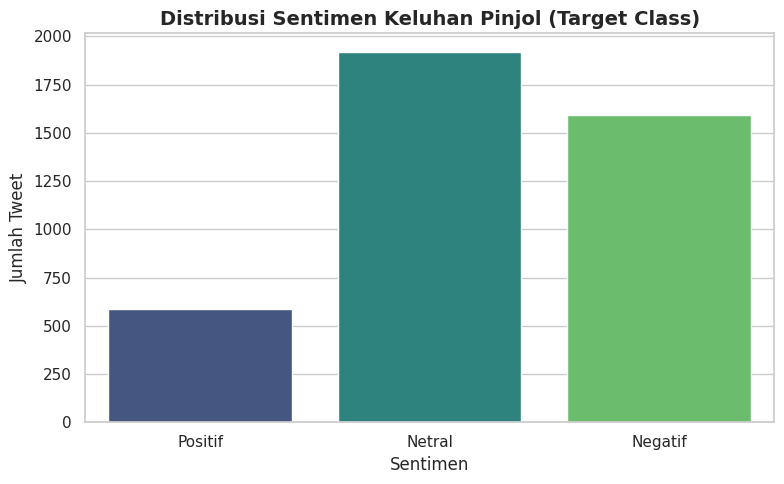

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# --- 1. Distribusi Label Sentimen (Target Class) ---
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Label_Sentimen', hue='Label_Sentimen', palette='viridis', legend=False)
plt.title('Distribusi Sentimen Keluhan Pinjol (Target Class)', fontsize=14, fontweight='bold')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Tweet')
plt.tight_layout()
plt.show()

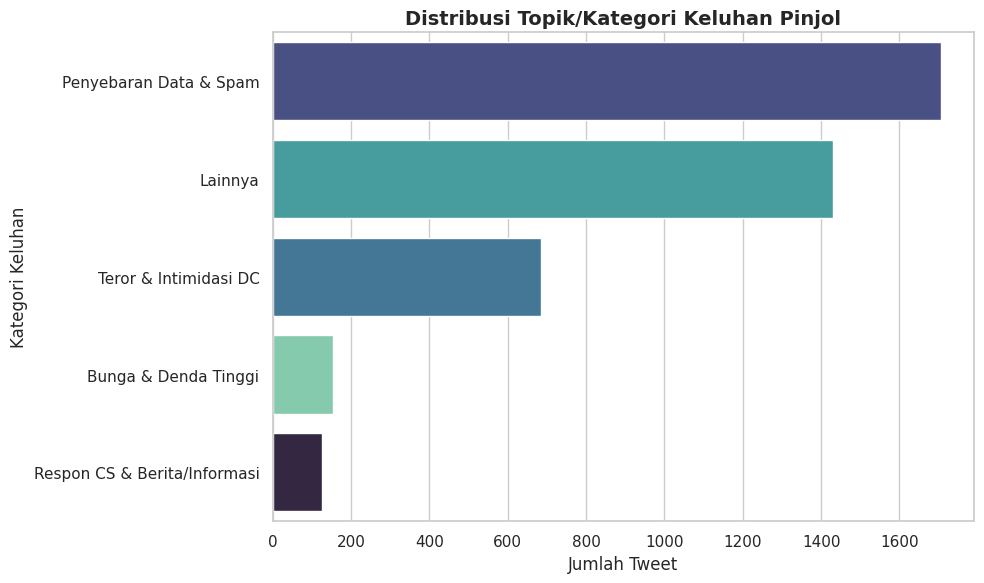

In [ ]:
# --- 2. Distribusi Kategori Keluhan ---
plt.figure(figsize=(10, 6))
order = df['Label_Kategori'].value_counts().index
sns.countplot(data=df, y='Label_Kategori', hue='Label_Kategori', palette='mako', order=order, legend=False)
plt.title('Distribusi Topik/Kategori Keluhan Pinjol', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Tweet')
plt.ylabel('Kategori Keluhan')
plt.tight_layout()
plt.show()

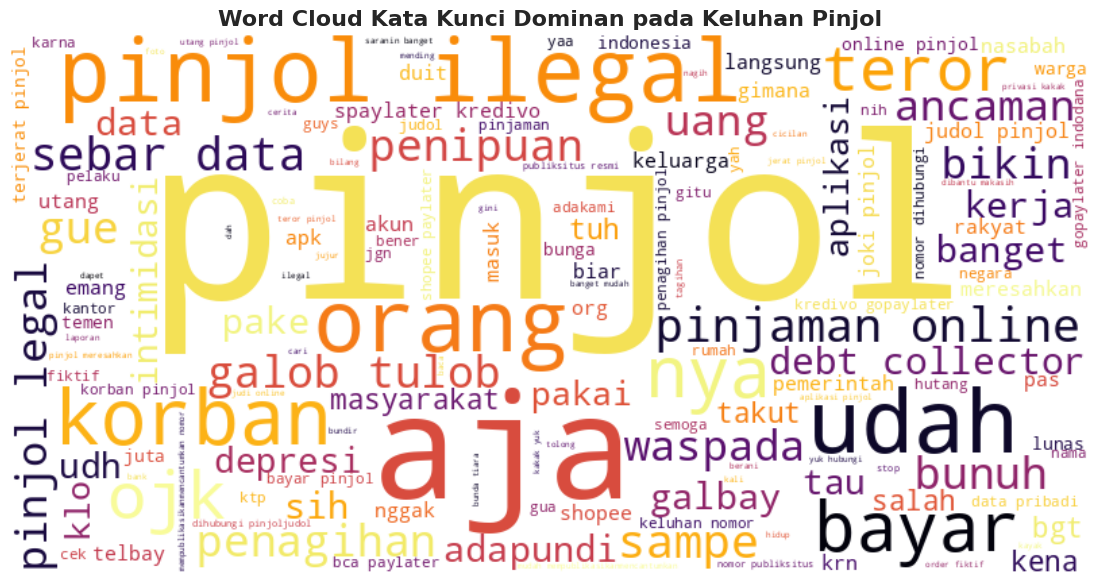

In [ ]:
# --- 3. Word Cloud Kata yang Sering Muncul ---
all_clean_words = ' '.join(df['Isi_Tweet_Clean'].dropna())

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='inferno',
    max_words=150
).generate(all_clean_words)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud Kata Kunci Dominan pada Keluhan Pinjol', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

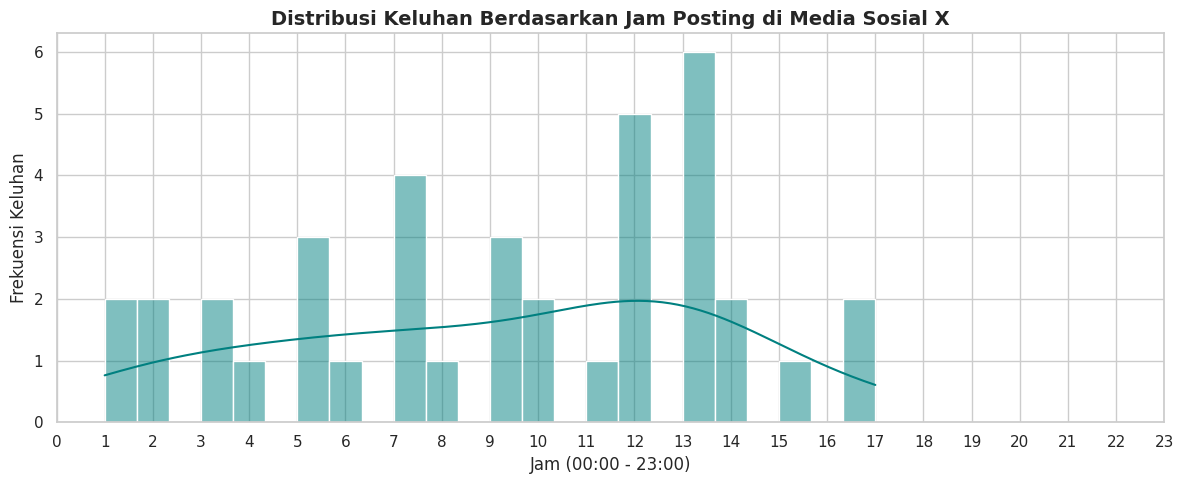

In [ ]:
# --- 4. Tren Waktu Posting Keluhan Berdasarkan Jam ---
# Ekstrak jam dari kolom Waktu Posting jika tipe datanya datetime
if pd.api.types.is_datetime64_any_dtype(df['Waktu Posting']):
    df['Jam_Posting'] = df['Waktu Posting'].dt.hour

    plt.figure(figsize=(12, 5))
    sns.histplot(data=df, x='Jam_Posting', bins=24, kde=True, color='teal')
    plt.title('Distribusi Keluhan Berdasarkan Jam Posting di Media Sosial X', fontsize=14, fontweight='bold')
    plt.xlabel('Jam (00:00 - 23:00)')
    plt.ylabel('Frekuensi Keluhan')
    plt.xticks(range(0, 24))
    plt.tight_layout()
    plt.show()
else:
    print("Kolom 'Waktu Posting' belum dalam format datetime atau kosong.")